# 图四：各月雨量对比

对应《项目总体计划》第三步：香港天文台站，研究范围 1991–2025 年 6–8 月。比较 **1991–2000** 与 **2016–2025**，每根柱子是时期内同月份“月总雨量”的跨年平均，单位 mm。

按顺序点击 Run All 即可。程序直接读取仓库三份 `data/raw` CSV，采用三种观测均完整且质量标记为 C 的完整夏季；与现有月指标和时期汇总表交叉核对。原始数据不修改。

课程参考：tutorial2sol 的 Matplotlib 导入、设置图幅、标题和横纵轴、显示图像步骤，以及其第 14 题的柱状图概念。分组柱和 PNG/SVG 导出为本项目补充；未套用概率分布数据。

## 1. 导入绘图库与设定目录
绘图采用课程中出现的 Matplotlib。早期蓝色、近期橙色，图三也应保持相同配色。

In [1]:
"""图四：从仓库三份原始 CSV 核对完整年份，绘制平均月雨量。"""
from pathlib import Path
import calendar
import csv
from datetime import date
import math
from statistics import mean

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

# 在 VS Code 中从项目根目录或 notebooks 目录运行。
ROOT = Path.cwd()
if not (ROOT / "data/raw").exists():
    ROOT = ROOT.parent
if not (ROOT / "data/raw").exists():
    raise FileNotFoundError("请在项目根目录或 notebooks 目录运行此 Notebook")
MONTHS = (6, 7, 8)
PERIODS = (("early_1991_2000", 1991, 2000), ("recent_2016_2025", 2016, 2025))
# 图三制作时也请使用这两个时期颜色。
COLORS = ("#246C8A", "#C05A37")



## 2. 读取原始日数据
CSV 前两行为标题；重复日期报错；缺失不填零。Trace 小于 0.05 mm，按项目计划以 0 近似。

In [2]:
def read_raw(filename, rainfall=False):
    """保留 C 标记的有效数值；Trace 按计划记作 0，缺失不填零。"""
    rows = {}
    with (ROOT / "data/raw" / filename).open(encoding="utf-8-sig", newline="") as f:
        next(f)
        next(f)
        for row in csv.DictReader(f):
            try:
                y, m, d = (int(row[k]) for k in ("年/Year", "月/Month", "日/Day"))
            except (ValueError, TypeError):
                continue  # 原始 CSV 末尾的说明行
            if not (1991 <= y <= 2025 and m in MONTHS):
                continue
            day = date(y, m, d)
            if day in rows:
                raise ValueError(f"Duplicate date: {filename}: {day}")
            value = row["數值/Value"]
            trace = rainfall and value == "Trace"
            try:
                number = 0.0 if trace else float(value)
            except (ValueError, TypeError):
                number = math.nan
            valid = row["數據完整性/data Completeness"] == "C" and math.isfinite(number)
            if rainfall and valid and number < 0:
                raise ValueError(f"Negative rainfall: {day}")
            rows[day] = (number, valid, trace)
    return rows



## 3. 检查完整夏季并计算平均月总雨量
每年必须有 92 个完整日。先将日雨量按年月相加，再将同一时期各年的同月份总量平均。最后核对仓库两个指标表。

In [3]:
def prepare_data():
    """每日求和 → 每年各月总量 → 时期内跨年平均，并核对已有指标。"""
    sources = [read_raw("daily_mean_temperature_hko.csv"),
               read_raw("daily_maximum_temperature_hko.csv"),
               read_raw("daily_rainfall_hko.csv", rainfall=True)]
    monthly, valid_years = {}, []
    for year in range(1991, 2026):
        days = [date(year, month, day) for month in MONTHS
                for day in range(1, calendar.monthrange(year, month)[1] + 1)]
        if not all(day in source and source[day][1] for day in days for source in sources):
            continue
        valid_years.append(year)
        for month in MONTHS:
            monthly[year, month] = math.fsum(sources[2][d][0] for d in days if d.month == month)
    # 与仓库每年各月指标逐项核对，防止绘图与小组表格不一致。
    with (ROOT / "data/metrics/monthly_summer_metrics.csv").open() as f:
        existing = {(int(r["year"]), int(r["month"])): float(r["monthly_total_rainfall_mm"])
                    for r in csv.DictReader(f)}
    if existing.keys() != monthly.keys() or any(
        not math.isclose(existing[k], v, abs_tol=1e-8) for k, v in monthly.items()
    ):
        raise ValueError("Raw data and monthly_summer_metrics.csv disagree")
    with (ROOT / "data/metrics/period_monthly_summary.csv").open() as f:
        summary = {(r["period"], int(r["month"])): r for r in csv.DictReader(f)}
    records = []
    for period, start, end in PERIODS:
        years = [y for y in valid_years if start <= y <= end]
        if not years:
            raise ValueError(f"No complete summers in {period}")
        for month in MONTHS:
            value = mean(monthly[y, month] for y in years)
            original = summary[period, month]
            if int(original["year_count"]) != len(years) or not math.isclose(
                value, float(original["average_monthly_total_rainfall_mm"]), abs_tol=1e-8
            ):
                raise ValueError("Raw data and period_monthly_summary.csv disagree")
            traces = sum(sources[2][d][2] for d in sources[2] if d.year in years and d.month == month)
            records.append(dict(period=period, month=month, year_count=len(years),
                                valid_years=";".join(map(str, years)),
                                average_monthly_total_rainfall_mm=value,
                                trace_upper_bound_mm=traces * 0.05 / len(years)))
    print(f"Verified {len(valid_years)} complete summers, {len(monthly)} monthly totals and 6 period means.")
    return records



In [4]:
records = prepare_data()
for r in records:
    print(r["period"], r["month"], r["year_count"], f'{r["average_monthly_total_rainfall_mm"]:.2f} mm')

Verified 35 complete summers, 105 monthly totals and 6 period means.
early_1991_2000 6 10 456.66 mm
early_1991_2000 7 10 443.26 mm
early_1991_2000 8 10 514.59 mm
recent_2016_2025 6 10 427.52 mm
recent_2016_2025 7 10 331.43 mm
recent_2016_2025 8 10 498.84 mm


## 4. 绘制分组柱状图并导出
纵轴从零开始；完整标注站点、范围、月份、单位、时期和实际样本数。字体与现有图五一致。保存 300 dpi PNG 和字体转路径的 SVG。

In [5]:
def make_figure(records):
    """与现有图五一致的字体、版式、PNG 分辨率和 SVG 字体路径。"""
    style = {"font.family": "DejaVu Sans", "font.size": 10,
             "text.color": "#243746", "axes.labelcolor": "#243746",
             "xtick.color": "#51616D", "ytick.color": "#51616D", "svg.fonttype": "path"}
    with plt.rc_context(style):
        fig, ax = plt.subplots(figsize=(8.6, 6.4), facecolor="white")
        fig.subplots_adjust(left=0.115, right=0.955, bottom=0.235, top=0.77)
        width = 0.32
        for i, (period, start, end) in enumerate(PERIODS):
            data = [r for r in records if r["period"] == period]
            bars = ax.bar([x + (i - 0.5) * width for x in range(3)],
                          [r["average_monthly_total_rainfall_mm"] for r in data],
                          width=width, color=COLORS[i], edgecolor="white", linewidth=0.7,
                          label=f"{start}–{end} (n = {data[0]['year_count']} years)", zorder=3)
            ax.bar_label(bars, fmt="%.2f", padding=5, fontsize=10)
        ax.set_xticks(range(3), ["June (6)", "July (7)", "August (8)"])
        ax.set_xlabel("Month", labelpad=12)
        ax.set_ylabel("Mean monthly total rainfall (mm)", labelpad=12)
        ymax = max(r["average_monthly_total_rainfall_mm"] for r in records)
        ax.set_ylim(0, math.ceil(ymax * 1.16 / 100) * 100)
        ax.grid(axis="y", color="#E5EAED", linewidth=0.7)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        for spine in ("left", "bottom"):
            ax.spines[spine].set_color("#B8C3CA")
        ax.tick_params(length=3, color="#B8C3CA")
        ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, frameon=False, fontsize=9)
        fig.text(0.115, 0.93, "Figure 4. Monthly rainfall comparison", fontsize=16, weight="bold")
        fig.text(0.115, 0.88, "Hong Kong Observatory · June–August · Study period: 1991–2025",
                 fontsize=10, color="#51616D")
        fig.text(0.115, 0.10, "Bars show the across-year mean of monthly totals; complete summers only.", fontsize=8.5, color="#51616D")
        fig.text(0.115, 0.06, "Source: project HKO daily CSVs. Trace (<0.05 mm) treated as 0 mm.", fontsize=8.5, color="#51616D")
        output = ROOT / "figures"
        output.mkdir(exist_ok=True)
        for ext in ("png", "svg"):
            path = output / f"04_monthly_rainfall_comparison.{ext}"
            fig.savefig(path, dpi=300, facecolor="white")
            print(path)
        plt.close(fig)



/Users/lizhuoman/Documents/ChatGPT/AMA2233/ama2233-hk-summer-weather/figures/04_monthly_rainfall_comparison.png
/Users/lizhuoman/Documents/ChatGPT/AMA2233/ama2233-hk-summer-weather/figures/04_monthly_rainfall_comparison.svg


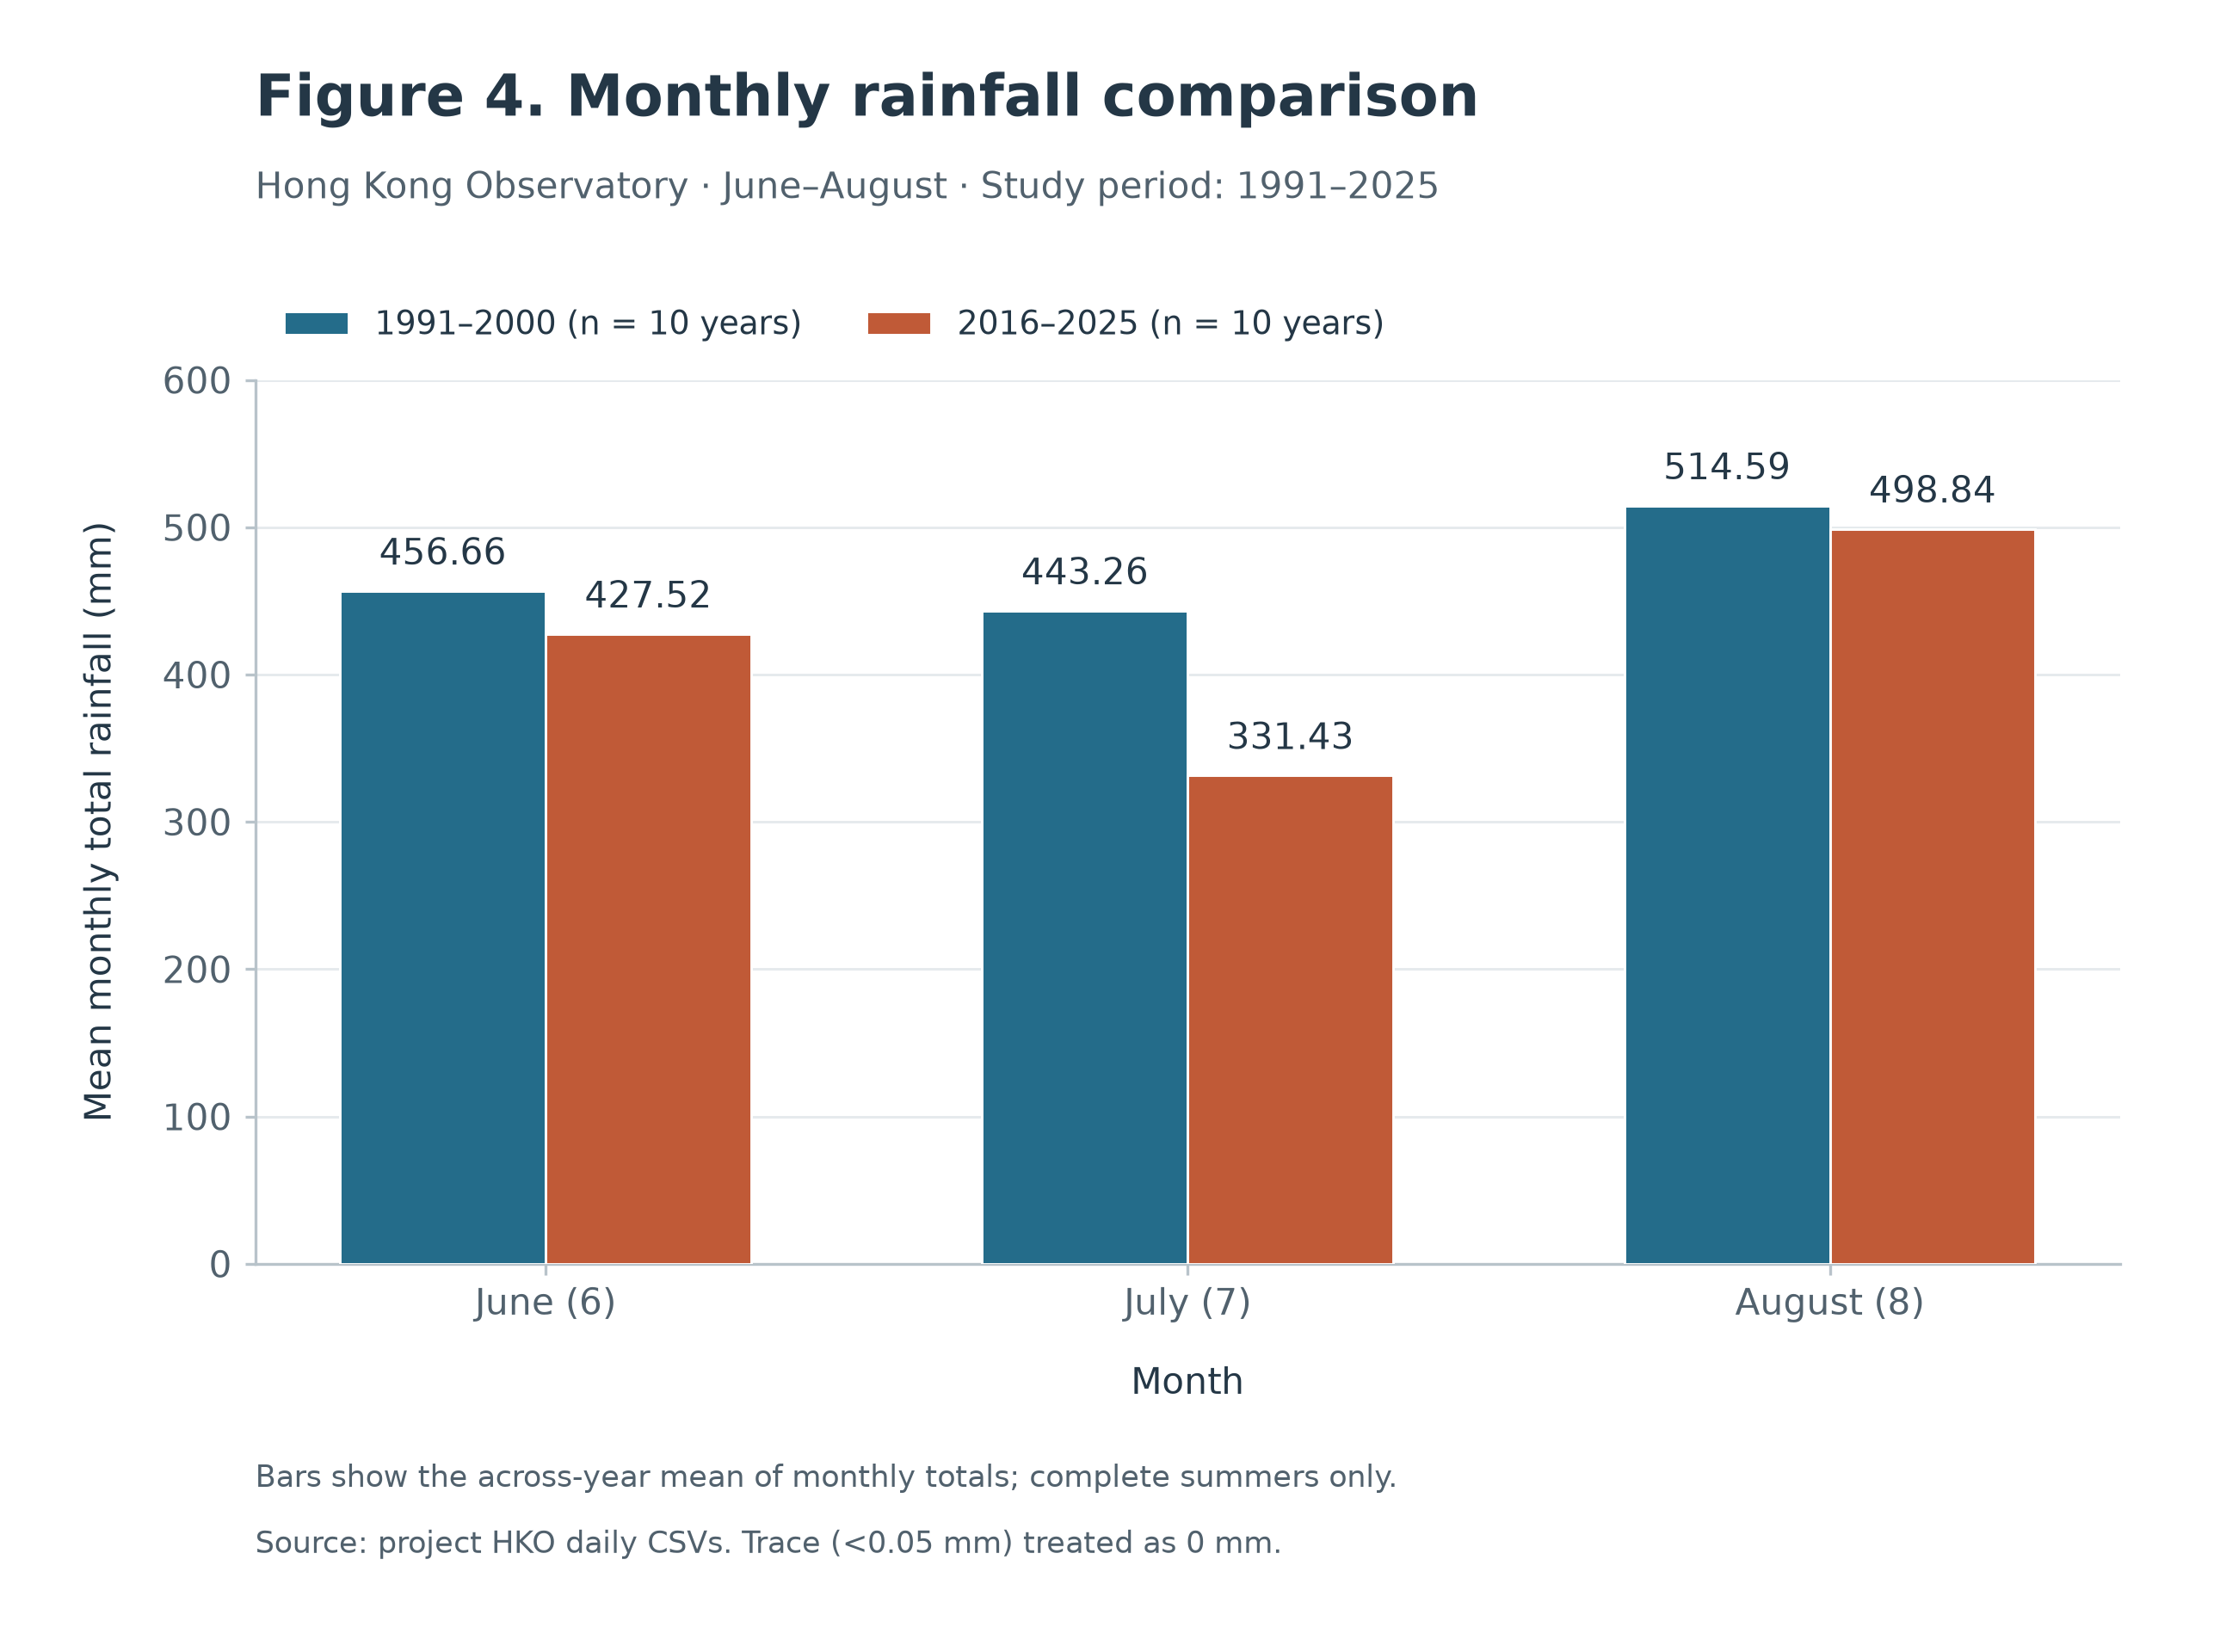

In [6]:
make_figure(records)
import csv
output = ROOT / "reports/figure04_values.csv"
output.parent.mkdir(exist_ok=True)
with output.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(records[0]))
    writer.writeheader()
    writer.writerows(records)
from IPython.display import Image, display
display(Image(filename=str(ROOT / "figures/04_monthly_rainfall_comparison.png"), width=860))

## 5. 结果说明

两个时期各有 10 个完整夏季。6、7、8 月早期均值分别为 456.66、443.26、514.59 mm，近期为 427.52、331.43、498.84 mm。近期减早期分别为 −29.14、−111.83、−15.75 mm，7 月差异最大，两个时期均以 8 月最高。

这些是两个指定时期的描述性比较，不能单凭柱形高度判断统计显著，也不能据此断言长期趋势或因果。Trace 近似造成的时期月均误差上界写在 `reports/figure04_values.csv` 的 `trace_upper_bound_mm`（真实误差严格小于该值）；不足以改变本图比较方向。